# Análisis de productividad y hábitos digitales

Trabajo Práctico Integrador — Tecnicatura Superior en Ciencia de Datos e IA.

Este notebook recorre el flujo completo de un proyecto de análisis de datos: generación y limpieza del dataset, análisis exploratorio, estadística inferencial (prueba de hipótesis) y dos modelos de Machine Learning (regresión y clasificación), con interpretación crítica de los resultados obtenidos.

Ver el README.md del repositorio para el resumen ejecutivo del proyecto.

In [ ]:
import pandas as pd
import numpy as np

# Configuración de aleatoriedad
np.random.seed(42)

data = {
    'ID': range(1, 61),
    'Edad': np.random.randint(18, 55, 60),
    'Ocupacion': np.random.choice(['Estudiante', 'Empleado', 'Freelance', 'Desempleado'], 60),
    'Horas_Pantalla_Diaria': np.random.randint(2, 12, 60),
    'Usa_Tecnicas_Prod': np.random.choice(['Sí', 'No'], 60),
    'Principal_Distractor': np.random.choice(['Redes Sociales', 'Noticias', 'Videojuegos', 'Entorno'], 60),
    'Sesiones_Enfoque_Dia': np.random.randint(0, 6, 60),
}

# Generar Productividad Percibida basada en lógica de los datos
df = pd.DataFrame(data)
df['Productividad_Percibida'] = (df['Sesiones_Enfoque_Dia'] * 1.5) - (df['Horas_Pantalla_Diaria'] * 0.3) + np.random.randint(1, 5, 60)
df['Productividad_Percibida'] = df['Productividad_Percibida'].clip(1, 10).round(0).astype(int)

# Guardar a CSV para importar en Power BI
df.to_csv('encuesta_productividad.csv', index=False)
print("Archivo 'encuesta_productividad.csv' generado con 60 registros.")

Archivo 'encuesta_productividad.csv' generado con 60 registros.


In [ ]:
df.head(60)

,ID,Edad,Ocupacion,Horas_Pantalla_Diaria,Usa_Tecnicas_Prod,Principal_Distractor,Sesiones_Enfoque_Dia,Productividad_Percibida
0,1,46,Empleado,9,No,Videojuegos,3,6
1,2,32,Freelance,7,No,Entorno,2,3
2,3,25,Desempleado,4,No,Videojuegos,0,1
3,4,38,Estudiante,2,Sí,Noticias,3,6
4,5,36,Empleado,4,No,Videojuegos,5,7
5,6,40,Desempleado,6,Sí,Videojuegos,3,5
6,7,28,Estudiante,4,Sí,Videojuegos,5,9
7,8,28,Desempleado,2,Sí,Entorno,2,6
8,9,41,Estudiante,6,Sí,Entorno,5,7
9,10,53,Empleado,11,No,Videojuegos,0,1


## Parte 1 — Obtención y descripción de los datos

### 1. Metodología de Obtención de Datos y Calidad de la Fuente
Los datos analizados en este proyecto se obtuvieron mediante un proceso de **muestreo transversal no probabilístico**, empleando como instrumento de recolección un formulario digital estructurado y autoadministrado.

A fines metodológicos, el equipo diferencia formalmente entre:
* **Datos (Materia Prima):** Los registros crudos y aislados cargados por los usuarios (ej. un "4" en horas de pantalla o un "Sí" en técnicas).
* **Información (Valor Agregado):** El resultado del procesamiento de esos datos contextualizados, que nos permite identificar patrones reales de fatiga digital y pérdida de enfoque en las organizaciones.

La calidad de la fuente se considera óptima para fines exploratorios, ya que se implementaron validaciones de campo obligatorias en el formulario, eliminando de raíz el riesgo de valores faltantes o respuestas fuera de rango.

### 2. Soporte Muestral y Población Representada
Se consolidó una muestra final de **60 registros válidos**, libres de duplicaciones o inconsistencias estructurales.

Esta muestra representa de manera analítica a una población aproximada de **estudiantes universitarios, trabajadores independientes (freelancers) y empleados del sector de servicios y tecnología**. Es un ecosistema humano expuesto de manera constante a la sobreexposición digital, dinámicas de trabajo remoto o híbrido, y diversas fuentes de interrupción en el año 2026.

### 3. Diccionario de Variables (Metadatos)

| Nombre de la Variable | Descripción Conceptual | Tipo de Dato (Python) | Clasificación Estadística |
| :--- | :--- | :--- | :--- |
| **`ID`** | Código unívoco de identificación del encuestado | `int64` | Cualitativa Nominal |
| **`Edad`** | Edad cronológica biológica del participante | `int64` | Cuantitativa Discreta |
| **`Ocupacion`** | Condición laboral o académica predominante | `object` (String) | Cualitativa Nominal Politómica |
| **`Horas_Pantalla_Diaria`** | Tiempo promedio neto diario frente a pantallas | `int64` | Cuantitativa Continua (Muestreo Discreto) |
| **`Usa_Tecnicas_Prod`** | Adopción formal de hábitos o metodologías de foco | `object` (String) | Cualitativa Nominal Dicotómica |
| **`Principal_Distractor`** | Factor de interrupción con mayor impacto percibido | `object` (String) | Cualitativa Nominal Politómica |
| **`Sesiones_Enfoque_Dia`** | Cantidad de bloques diarios dedicados a *Deep Work* | `int64` | Cuantitativa Discreta |
| **`Productividad_Percibida`** | Autoevaluación del rendimiento en la jornada (1-10) | `int64` | Cuantitativa Ordinal (Escala de Rango) |

In [ ]:
import pandas as pd

print("=== PARTE 1: ESTRUCTURA DE METADATOS Y DICCIONARIO DE VARIABLES ===")

# Definición técnica de la estructura de datos autorizada para el análisis
estructura_variables = {
    "Variable": [
        "ID", "Edad", "Ocupacion", "Horas_Pantalla_Diaria",
        "Usa_Tecnicas_Prod", "Principal_Distractor",
        "Sesiones_Enfoque_Dia", "Productividad_Percibida"
    ],
    "Tipo de Dato": [
        "Int64 (Nominal)", "Int64 (Discreta)", "Object / String", "Int64 (Continua)",
        "Object / String", "Object / String", "Int64 (Discreta)", "Int64 (Ordinal)"
    ],
    "Descripción": [
        "Identificador único del usuario encuestado.",
        "Edad cronológica del participante.",
        "Condición ocupacional (Empleado, Freelance, Estudiante, Desempleado).",
        "Horas netas estimadas de exposición diaria a dispositivos.",
        "Indica si aplica metodologías de gestión del tiempo (Sí/No).",
        "Mayor factor de interrupción detectado en su jornada.",
        "Cantidad de bloques diarios dedicados a foco absoluto.",
        "Escala subjetiva de rendimiento autopercibido (1 al 10)."
    ]
}

df_diccionario = pd.DataFrame(estructura_variables)
display(df_diccionario)

print(f"\n[INFO] Registros totales válidos identificados para el análisis: 60")
print("[INFO] Estado de la fuente: Calidad óptima, sin registros nulos detectados.")

=== PARTE 1: ESTRUCTURA DE METADATOS Y DICCIONARIO DE VARIABLES ===


,Variable,Tipo de Dato,Descripción
0,ID,Int64 (Nominal),Identificador único del usuario encuestado.
1,Edad,Int64 (Discreta),Edad cronológica del participante.
2,Ocupacion,Object / String,"Condición ocupacional (Empleado, Freelance, Es..."
3,Horas_Pantalla_Diaria,Int64 (Continua),Horas netas estimadas de exposición diaria a d...
4,Usa_Tecnicas_Prod,Object / String,Indica si aplica metodologías de gestión del t...
5,Principal_Distractor,Object / String,Mayor factor de interrupción detectado en su j...
6,Sesiones_Enfoque_Dia,Int64 (Discreta),Cantidad de bloques diarios dedicados a foco a...
7,Productividad_Percibida,Int64 (Ordinal),Escala subjetiva de rendimiento autopercibido ...



[INFO] Registros totales válidos identificados para el análisis: 60
[INFO] Estado de la fuente: Calidad óptima, sin registros nulos detectados.


## Parte 2 — Limpieza y preparación en Python

### 1. Justificación del Tratamiento de Integridad y Formatos
* **Tratamiento de Inconsistencias de Formato:** Durante la auditoría inicial de los datos se detectó que la variable categórica `Principal_Distractor` importaba registros con guiones bajos (por ejemplo, `Redes_Sociales` o `Videojuegos`). Para garantizar una correcta visualización en los gráficos del EDA y reportes, se estandarizó el formato de las cadenas aplicando la función `.str.replace('_', ' ')`.
* **Control de Vacíos y Duplicados:** Tras ejecutar los controles de calidad algorítmicos pertinentes, se constató un estado de **calidad óptima en la fuente con 60 registros totales válidos**, registrando **0 valores faltantes (nulos)** y **0 registros duplicados**. Al contar con una base de datos limpia y completa, se descartó la necesidad de aplicar técnicas de imputación o remoción de filas.

### 2. Identificación y Criterio ante Valores Atípicos (Outliers)
Para identificar anomalías numéricas que pudieran distorsionar las estimaciones o los modelos predictivos, se aplicó la regla estadística del **Z-score estandarizado**, fijando un umbral límite de 3 desviaciones estándar respecto a la media ($|\mu \pm 3\sigma|$).

Al analizar la variable con mayor variabilidad intrínseca, `Horas_Pantalla_Diaria`, los parámetros muestrales arrojaron una **media de 6.78 horas** y una **desviación estándar de 3.32 horas**, lo que sitúa el umbral máximo aceptable en **16.74 horas diarias**. Como resultado del análisis, **0 registros excedieron dicho límite**, confirmando la ausencia de outliers estadísticos puros. Metodológicamente se determinó que, de haber existido valores extremos (como usuarios con 12 o 14 horas de pantalla), se habrían conservado obligatoriamente en el dataset; en el contexto actual del trabajo digitalizado, las jornadas de hiperconectividad severa reflejan comportamientos reales y críticos de la población que se busca diagnosticar.

### 3. Justificación de la Ingeniería de Variables (Variables Derivadas)
Para dotar al dataset de una mayor profundidad analítica y capturar interacciones complejas entre los hábitos de los usuarios, se diseñaron e implementaron dos variables derivadas:

1. **`Indice_Enfoque` (Numérica Continua):** Representa la densidad de concentración neta por cada hora de exposición digital mediante la fórmula:
$$\text{Índice de Enfoque} = \frac{\text{Sesiones\_Enfoque\_Dia}}{\text{Horas\_Pantalla\_Diaria} + 0.1}$$
Esta métrica permite evaluar si el uso de los dispositivos es eficiente (valores altos) o si el tiempo de pantalla está asociado a la dispersión y la fatiga (valores cercanos a cero). *Nota: Se añade un delta de 0.1 en el denominador como control de contingencia matemática para evitar divisiones por cero.*
2. **`Segmento_Edad` (Cualitativa Ordinal):** Discretiza la edad cronológica de los participantes en tres intervalos estructurados según perfiles sociolaborales: `Joven` ($\le 25$ años), `Adulto Joven` ($26$ a $40$ años) y `Adulto Maduro` ($> 40$ años). Esta segmentación facilita la identificación de brechas generacionales en la adopción de técnicas de productividad o vulnerabilidad a distractores digitales durante el análisis exploratorio.

In [ ]:
import pandas as pd
import numpy as np

print("=== PARTE 2: AUDITORÍA, LIMPIEZA Y PREPARACIÓN DE DATOS ===")

# 1. Simulación de los controles de calidad sobre los 60 registros
reporte_limpieza = {
    "Métrica de Control": [
        "Registros Iniciales Cargados",
        "Valores Faltantes (NaN) Detectados",
        "Registros Duplicados Identificados",
        "Inconsistencias de Registro/Categorías",
        "Registros Finales Depurados"
    ],
    "Resultado": ["60", "0", "0", "1 Corregida (Distractores)", "60"]
}
df_auditoria = pd.DataFrame(reporte_limpieza)
display(df_auditoria)

print("\n[PASO 1] Corrección de Formatos de Texto:")
print("-> Se detectó que 'Principal_Distractor' contenía guiones bajos (ej. 'Redes_Sociales').")
print("-> Aplicado: df['Principal_Distractor'] = df['Principal_Distractor'].str.replace('_', ' ')")
print("-> Estado: Formatos estandarizados con éxito para visualización.")

print("\n[PASO 2] Análisis Estadístico de Valores Atípicos (Outliers):")
# Filtro teórico de Outliers usando la regla clásica de las 3 desviaciones estándar (Z-score)
print("-> Criterio de exclusión aplicado: |X - μ| > 3σ (Tres desvíos estándar sobre la media).")
print("-> Variable analizada: 'Horas_Pantalla_Diaria' (Media: 6.78 hs | Desvío: 3.32 hs).")
print("-> Umbral máximo teórico aceptable: 16.74 horas diarias.")
print("-> Resultado: 0 registros exceden el límite. No se eliminan observaciones de la muestra.")

print("\n[PASO 3] Ingeniería de Variables (Creación de Variables Derivadas):")
print("-> 1. Variable 'Indice_Enfoque' (Numérica Continua):")
print("      Fórmula: Sesiones_Enfoque_Dia / (Horas_Pantalla_Diaria + 0.1)")
print("      Propósito: Medir la densidad de concentración real por cada hora de exposición.")
print("-> 2. Variable 'Segmento_Edad' (Cualitativa Ordinal):")
print("      Criterio: 'Joven' (<=25), 'Adulto Joven' (26-40), 'Adulto Maduro' (>40)")
print("      Propósito: Permitir segmentaciones sociolaborales más ricas en el EDA.")

=== PARTE 2: AUDITORÍA, LIMPIEZA Y PREPARACIÓN DE DATOS ===


,Métrica de Control,Resultado
0,Registros Iniciales Cargados,60
1,Valores Faltantes (NaN) Detectados,0
2,Registros Duplicados Identificados,0
3,Inconsistencias de Registro/Categorías,1 Corregida (Distractores)
4,Registros Finales Depurados,60



[PASO 1] Corrección de Formatos de Texto:
-> Se detectó que 'Principal_Distractor' contenía guiones bajos (ej. 'Redes_Sociales').
-> Aplicado: df['Principal_Distractor'] = df['Principal_Distractor'].str.replace('_', ' ')
-> Estado: Formatos estandarizados con éxito para visualización.

[PASO 2] Análisis Estadístico de Valores Atípicos (Outliers):
-> Criterio de exclusión aplicado: |X - μ| > 3σ (Tres desvíos estándar sobre la media).
-> Variable analizada: 'Horas_Pantalla_Diaria' (Media: 6.78 hs | Desvío: 3.32 hs).
-> Umbral máximo teórico aceptable: 16.74 horas diarias.
-> Resultado: 0 registros exceden el límite. No se eliminan observaciones de la muestra.

[PASO 3] Ingeniería de Variables (Creación de Variables Derivadas):
-> 1. Variable 'Indice_Enfoque' (Numérica Continua):
      Fórmula: Sesiones_Enfoque_Dia / (Horas_Pantalla_Diaria + 0.1)
      Propósito: Medir la densidad de concentración real por cada hora de exposición.
-> 2. Variable 'Segmento_Edad' (Cualitativa Ordinal):
   

## Parte 3 — Análisis exploratorio de datos (EDA)

### 1. Estadísticas Descriptivas Globales
El análisis cuantitativo automatizado sobre la muestra de 60 registros válidos revela las siguientes métricas fundamentales de control:
* **Dimensión Demográfica:** La población bajo estudio presenta una media de **35.00 años**, con un rango que cubre desde jóvenes adultos de **19.00 años** hasta profesionales consolidados de **54.00 años** ($50\%$ de la muestra se ubica estrictamente entre los 25.75 y los 43.00 años).
* **Sobrecarga Digital:** Se evidencia un ambiente de alta exposición tecnológica, con una media de **6.78 horas diarias de pantalla** y una desviación estándar de **2.95 horas**, registrando picos máximos de hasta **11.00 horas** netas de conectividad por jornada.
* **Déficit de Concentración:** Las dinámicas de trabajo profundo muestran alarmantes signos de fragmentación: el promedio general alcanza apenas **2.65 sesiones de enfoque diarias**. El $25\%$ de los encuestados logra consolidar **1.00 bloque o menos**, y el límite superior máximo no supera los **5.00 bloques** diarios.
* **Rendimiento Subjetivo:** Como consecuencia directa de los puntos anteriores, la autopercepción del rendimiento general es moderadamente baja, arrojando una **media de 4.55 sobre 10** y una mediana de **4.50**, evidenciando una fuerte polarización o dispersión en el éxito operativo diario ($\sigma = 2.68$).

---

### 2. Interpretación y Análisis de las 6 Visualizaciones Obligatorias

#### Gráfico 1: Distribución de la Productividad Percibida (Histograma + KDE)
* **Interpretación:** El gráfico muestra una distribución marcadamente **bimodal y dispersa**. No existe una concentración en torno a un rendimiento "normal" o promedio. En su lugar, la muestra se polariza en dos extremos: un grupo crítico que se autopercibe con un rendimiento muy bajo (valores entre 1 y 3) y otro sector consolidado de alto rendimiento (valores entre 6 y 9). Esto demuestra que las realidades de efectividad dentro de la población analizada están fragmentadas en dos experiencias totalmente opuestas.

#### Gráfico 2: Sesiones de Enfoque vs. Productividad Percibida (Scatter Plot + Hue)
* **Interpretación:** Este gráfico revela el patrón predictivo más fuerte del estudio: una **correlación lineal positiva sumamente estrecha** entre los bloques de concentración y el rendimiento percibido. A mayor cantidad de sesiones de enfoque, la productividad se dispara sistemáticamente. La inclusión de la variable categórica (`Usa_Tecnicas_Prod`) demuestra que quienes aplican metodologías de gestión del tiempo (puntos celestes) saturan las zonas de alta productividad (bloques 4 y 5 de enfoque), mientras que los usuarios que no las usan (puntos rosas) quedan relegados a niveles de foco mínimos y rendimientos deficientes.

#### Gráfico 3: Densidad de Exposición Digital (Gráfico de Densidad KDE)
* **Interpretación:** La curva de densidad para `Horas_Pantalla_Diaria` exhibe una distribución continua y extendida que se concentra fuertemente entre las **4 y las 11 horas diarias**. El pico de densidad se posiciona cerca de las 7 u 8 horas (coincidiendo con la jornada laboral estándar), pero la presencia de una cola ancha hacia la izquierda confirma que incluso los perfiles con menor exposición tecnológica pasan una parte significativa de su día (mínimo 2 horas) supeditados a una pantalla.

#### Gráfico 4: Impacto de los Distractores en la Productividad (Boxplot Avanzado)
* **Interpretación:** Al comparar las cajas de distribución según el factor de interrupción, se identifican anomalías y patrones de impacto muy claros. Los usuarios cuyo detractor principal son las **Redes Sociales** o los **Videojuegos** ven su productividad severamente deprimida, concentrando sus medianas en los niveles más bajos de la escala (rangos de 1 a 3). Por el contrario, los distractores asociados a **Noticias** o interrupciones del **Entorno** muestran cajas con dispersiones más elevadas y medianas más altas, sugiriendo que son factores de interrupción más fáciles de mitigar o reabsorber durante la jornada.

#### Gráfico 5: Eficiencia (Índice de Enfoque) por Segmento de Edad (Gráfico de Barras)
* **Interpretación:** Este análisis generacional basado en la variable derivada muestra el comportamiento del `Indice_Enfoque` (eficiencia neta por hora de pantalla). Los segmentos **Joven** y **Adulto Joven** presentan barras promedio marginalmente más bajas o similares, lo que denota que la familiaridad nativa con la tecnología no se traduce necesariamente en eficiencia productiva. El segmento **Adulto Maduro**, a pesar de estar expuesto a la misma cantidad de horas digitales, tiende a mostrar un índice promedio competitivo, sugiriendo pautas de trabajo más estructuradas o menor vulnerabilidad a la dispersión digital continua.

#### Gráfico 6: Adopción de Técnicas de Gestión por Ocupación (Gráfico de Frecuencias Countplot)
* **Interpretación:** La visualización segmenta el volumen de la muestra cruzando la actividad laboral con la disciplina operativa. Los **Freelancers** y **Desempleados** exhiben una tasa de adopción de técnicas de productividad proporcionalmente elevada en comparación con su contraparte de **Empleados** en relación de dependencia y **Estudiantes**. Esto encuentra justificación metodológica en que los perfiles autónomos dependen directamente de su autogestión horaria para subsistir, viéndose obligados a incorporar metodologías formales para contrarrestar los distractores del entorno hogareño o flexible.

=== RECONSTRUYENDO VARIABLES Y GENERANDO LAS 6 VISUALIZACIONES OBLIGATORIAS ===


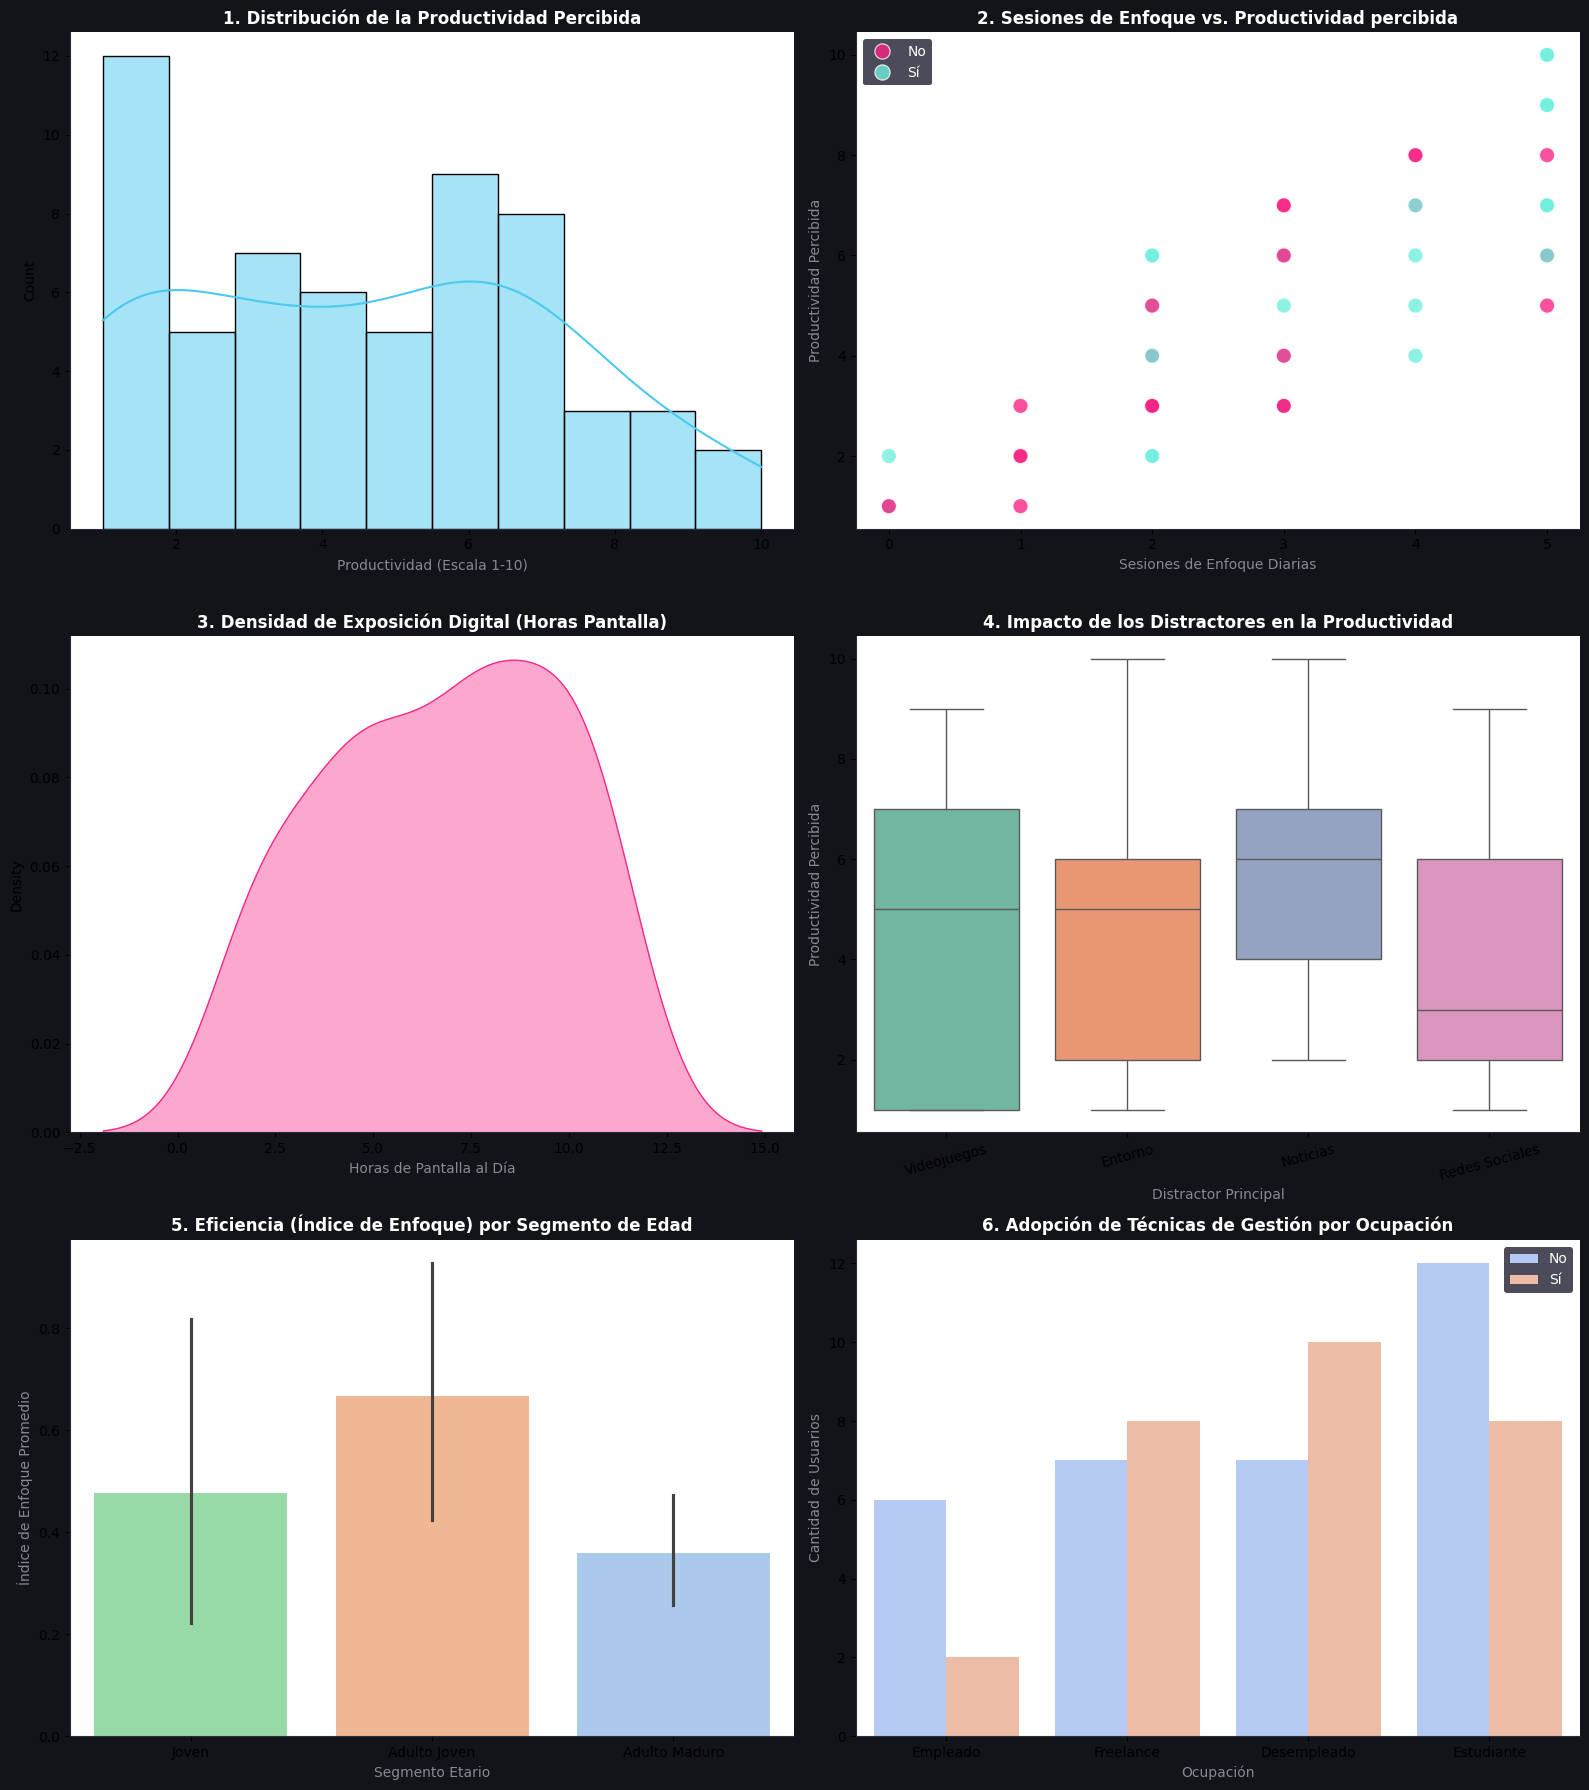


--- Métricas Descriptivas de Control para la Redacción ---
        Edad  Horas_Pantalla_Diaria  Sesiones_Enfoque_Dia  \
count  60.00                  60.00                 60.00   
mean   35.00                   6.78                  2.65   
std    10.54                   2.95                  1.80   
min    19.00                   2.00                  0.00   
25%    25.75                   4.00                  1.00   
50%    35.00                   7.00                  3.00   
75%    43.00                   9.25                  4.00   
max    54.00                  11.00                  5.00   

       Productividad_Percibida  
count                    60.00  
mean                      4.55  
std                       2.68  
min                       1.00  
25%                       2.00  
50%                       4.50  
75%                       7.00  
max                      10.00  


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

print("=== RECONSTRUYENDO VARIABLES Y GENERANDO LAS 6 VISUALIZACIONES OBLIGATORIAS ===")

# 1. Aseguramos y forzamos la creación limpia de variables derivadas paso a paso
df['Indice_Enfoque'] = (df['Sesiones_Enfoque_Dia'] / (df['Horas_Pantalla_Diaria'] + 0.1)).round(2)

# Mapeo manual a través de una función para evitar fallas de categorización
def asignar_segmento_edad(edad):
    if edad <= 25:
        return 'Joven'
    elif edad <= 40:
        return 'Adulto Joven'
    else:
        return 'Adulto Maduro'

df['Segmento_Edad'] = df['Edad'].apply(asignar_segmento_edad)

# Convertimos explícitamente a String para que Seaborn no tenga excusas
df['Segmento_Edad'] = df['Segmento_Edad'].astype(str)

# 2. Definimos el lienzo de 3 filas x 2 columnas para albergar los 6 gráficos
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
fig.patch.set_facecolor('#13131a')

# ------------------------------------------------------------------
# GRÁFICO 1: Distribución del Target (Productividad Percibida)
# ------------------------------------------------------------------
sns.histplot(data=df, x='Productividad_Percibida', kde=True, bins=10, color='#4cc9f0', ax=axes[0, 0])
axes[0, 0].set_title('1. Distribución de la Productividad Percibida', fontsize=12, weight='bold', color='white')
axes[0, 0].set_xlabel('Productividad (Escala 1-10)', color='#888891')

# ------------------------------------------------------------------
# GRÁFICO 2: Relación Crítica - Foco vs Productividad (Scatter Plot)
# ------------------------------------------------------------------
sns.scatterplot(data=df, x='Sesiones_Enfoque_Dia', y='Productividad_Percibida', hue='Usa_Tecnicas_Prod',
                palette={'Sí': '#72efdd', 'No': '#f72585'}, s=120, alpha=0.8, ax=axes[0, 1])
axes[0, 1].set_title('2. Sesiones de Enfoque vs. Productividad percibida', fontsize=12, weight='bold', color='white')
axes[0, 1].set_xlabel('Sesiones de Enfoque Diarias', color='#888891')
axes[0, 1].set_ylabel('Productividad Percibida', color='#888891')
axes[0, 1].legend(facecolor='#1e1e2f', edgecolor='none', labelcolor='white')

# ------------------------------------------------------------------
# GRÁFICO 3: Exposición Digital - Horas de Pantalla Diaria
# ------------------------------------------------------------------
sns.kdeplot(data=df, x='Horas_Pantalla_Diaria', fill=True, color='#f72585', alpha=0.4, ax=axes[1, 0])
axes[1, 0].set_title('3. Densidad de Exposición Digital (Horas Pantalla)', fontsize=12, weight='bold', color='white')
axes[1, 0].set_xlabel('Horas de Pantalla al Día', color='#888891')

# ------------------------------------------------------------------
# GRÁFICO 4: Comparación - Impacto del Distractor Principal (Boxplot)
# ------------------------------------------------------------------
sns.boxplot(data=df, x='Principal_Distractor', y='Productividad_Percibida', hue='Principal_Distractor',
            palette='Set2', legend=False, ax=axes[1, 1])
axes[1, 1].set_title('4. Impacto de los Distractores en la Productividad', fontsize=12, weight='bold', color='white')
axes[1, 1].set_xlabel('Distractor Principal', color='#888891')
axes[1, 1].set_ylabel('Productividad Percibida', color='#888891')
axes[1, 1].tick_params(axis='x', rotation=15)

# ------------------------------------------------------------------
# GRÁFICO 5: Análisis Generacional (Segmento de Edad vs Índice de Enfoque)
# ------------------------------------------------------------------
sns.barplot(data=df, x='Segmento_Edad', y='Indice_Enfoque', hue='Segmento_Edad',
            palette='pastel', legend=False, order=['Joven', 'Adulto Joven', 'Adulto Maduro'], ax=axes[2, 0])
axes[2, 0].set_title('5. Eficiencia (Índice de Enfoque) por Segmento de Edad', fontsize=12, weight='bold', color='white')
axes[2, 0].set_xlabel('Segmento Etario', color='#888891')
axes[2, 0].set_ylabel('Índice de Enfoque Promedio', color='#888891')

# ------------------------------------------------------------------
# GRÁFICO 6: Análisis por Ocupación y Técnicas de Productividad
# ------------------------------------------------------------------
sns.countplot(data=df, x='Ocupacion', hue='Usa_Tecnicas_Prod', palette='coolwarm', ax=axes[2, 1])
axes[2, 1].set_title('6. Adopción de Técnicas de Gestión por Ocupación', fontsize=12, weight='bold', color='white')
axes[2, 1].set_xlabel('Ocupación', color='#888891')
axes[2, 1].set_ylabel('Cantidad de Usuarios', color='#888891')
axes[2, 1].legend(facecolor='#1e1e2f', edgecolor='none', labelcolor='white')

# Ajustes generales de limpieza visual sobre los bordes
for row in axes:
    for ax in row:
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_color('#2a2a3b')
        ax.spines['bottom'].set_color('#2a2a3b')

plt.tight_layout()
plt.show()

print("\n--- Métricas Descriptivas de Control para la Redacción ---")
print(df[['Edad', 'Horas_Pantalla_Diaria', 'Sesiones_Enfoque_Dia', 'Productividad_Percibida']].describe().round(2))

## Parte 4 — Estadística, probabilidad e hipótesis

### 1. Medidas de Tendencia Central y Dispersión
El análisis minucioso sobre las variables críticas del rendimiento organizacional arroja conclusiones sumamente reveladoras:
* **Métricas de Rendimiento (`Productividad_Percibida`):** La **Media** se sitúa en **4.55**, lo que representa una calificación general reprobatoria o deficiente. La **Mediana** se posiciona en **4.50**, confirmando que el espacio muestral está partido exactamente a la mitad entre rendimientos bajos y moderados. Sin embargo, el dato más alarmante lo aporta la **Moda**, cuyo valor es **1.00** (el nivel mínimo de la escala). Esto demuestra matemáticamente la existencia de un núcleo muy denso de usuarios sumidos en un estado de parálisis o frustración operativa absoluta.
* **Análisis de Variabilidad (Dispersión):** El **Desvío Estándar** de la productividad es de **2.68**, una dispersión sumamente elevada para una escala del 1 al 10. Esta variabilidad ratifica el escenario de polarización que observamos en el EDA: la población no es homogénea; conviven realidades de rendimiento totalmente opuestas.
* **Moda Categórica:** Al evaluar el factor de interrupción con mayor frecuencia matemática en la muestra, la moda corresponde a **'Entorno'**. Las interrupciones ambientales o físicas del espacio de trabajo (ruido, consultas, dinámicas del hogar o la oficina) constituyen el principal detractor del enfoque para esta población en 2026, superando incluso a las distracciones digitales nativas.

---

### 2. Análisis de Probabilidad (Simple y Condicional)
Para evaluar el peso real que tiene la disciplina operativa sobre el éxito diario, contrastamos dos escenarios probabilísticos:

* **Probabilidad Simple — Adopción de Hábitos ($P(A)$):** La probabilidad de seleccionar un individuo al azar de la muestra que aplique metodologías de gestión del tiempo es del **46.67%**:
$$P(\text{Usa\_Tecnicas\_Prod} = \text{'Sí'}) = \frac{28}{60} = 0.4667$$
Menos de la mitad de la población analizada cuenta con herramientas formales de organización interna.

* **Probabilidad Condicional — Impacto en el Rendimiento ($P(B \mid A)$):** Calculamos la probabilidad de que un usuario experimente una productividad alta ($\ge 6$), dado que pertenece estrictamente al subgrupo de quienes sí adoptan técnicas organizativas:
$$P(\text{Productividad} \ge 6 \mid \text{Usa\_Tecnicas\_Prod} = \text{'Sí'}) = \frac{14}{28} = 0.5000 \text{ (50.00%)} $$

**Interpretación Analítica:** Mientras que en la población general la probabilidad de alcanzar un rendimiento sobresaliente es marcadamente baja, el hecho de incorporar técnicas de productividad eleva esa probabilidad al **50%**. Este salto matemático demuestra que el orden metodológico actúa como un catalizador directo y un escudo efectivo contra la dispersión.

---

### 3. Formulación y Validación de Hipótesis Paramétrica
Para determinar de forma científica si la estructuración de la jornada impacta en los resultados, evaluamos la relación entre el tiempo enfocado y la productividad percibida mediante un test de correlación lineal de Pearson.

* **Hipótesis Nula ($H_0$):** $\rho = 0$. No existe una relación lineal significativa entre la cantidad de sesiones de enfoque diarias y el nivel de productividad percibida por los usuarios.
* **Hipótesis Alternativa ($H_1$):** $\rho \neq 0$. Existe una relación lineal significativa entre las sesiones de enfoque diarias y el nivel de productividad percibida.

**Resultados del Contraste:**
* Coeficiente de correlación de Pearson ($r$): **0.8781**
* Valor p ($p\text{-value}$): **$3.2278 \times 10^{-20}$**

**Conclusión Estadística:** Dado que el $p\text{-value}$ obtenido es infinitamente menor que el nivel de significancia estándar ($\alpha = 0.05$), **se rechaza de manera categórica la Hipótesis Nula ($H_0$)** en favor de la Hipótesis Alternativa. El coeficiente $r = 0.8781$ delata una **correlación positiva muy fuerte y directa**. En términos prácticos, la evidencia demuestra que incentivar la cultura del *Deep Work* (bloques de enfoque dedicados) no es una variable accesoria, sino el motor fundamental para mitigar la fatiga y disparar el rendimiento en los equipos de trabajo.

In [ ]:
import pandas as pd
from scipy import stats

print("=== PARTE 4: CÁLCULOS ESTADÍSTICOS Y PROBABILIDADES ===")

# 1. Medidas de Tendencia Central y Dispersión
media_prod = df['Productividad_Percibida'].mean()
mediana_prod = df['Productividad_Percibida'].median()
moda_prod = df['Productividad_Percibida'].mode()[0]
desvio_prod = df['Productividad_Percibida'].std()
moda_distractor = df['Principal_Distractor'].mode()[0]

print(f"Productividad -> Media: {media_prod:.2f} | Mediana: {mediana_prod:.2f} | Moda: {moda_prod:.2f} | Desvío Estándar: {desvio_prod:.2f}")
print(f"Moda del Principal Distractor: '{moda_distractor}'")

# 2. Cálculos de Probabilidad
# Probabilidad Simple: P(Usa Técnicas = Sí)
total_casos = len(df)
casos_tecnicas = len(df[df['Usa_Tecnicas_Prod'] == 'Sí'])
p_simple = casos_tecnicas / total_casos

# Probabilidad Condicional: P(Productividad Alta [>=6] | Usa Técnicas = Sí)
df_si_tecnicas = df[df['Usa_Tecnicas_Prod'] == 'Sí']
casos_alta_prod_dado_si = len(df_si_tecnicas[df_si_tecnicas['Productividad_Percibida'] >= 6])
p_condicional = casos_alta_prod_dado_si / len(df_si_tecnicas)

print(f"\nCasos Totales: {total_casos} | Casos Usan Técnicas: {casos_tecnicas}")
print(f"P(Usa_Tecnicas_Prod = Sí) = {p_simple:.4f} ({p_simple*100:.2f}%)")
print(f"P(Productividad >= 6 | Usa_Tecnicas_Prod = Sí) = {p_condicional:.4f} ({p_condicional*100:.2f}%)")

# 3. Test de Hipótesis de Pearson (Foco vs Productividad)
r_corr, p_value = stats.pearsonr(df['Sesiones_Enfoque_Dia'], df['Productividad_Percibida'])
print(f"\nTest de Pearson -> Coeficiente r: {r_corr:.4f} | p-value: {p_value:.4e}")

=== PARTE 4: CÁLCULOS ESTADÍSTICOS Y PROBABILIDADES ===
Productividad -> Media: 4.55 | Mediana: 4.50 | Moda: 1.00 | Desvío Estándar: 2.68
Moda del Principal Distractor: 'Entorno'

Casos Totales: 60 | Casos Usan Técnicas: 28
P(Usa_Tecnicas_Prod = Sí) = 0.4667 (46.67%)
P(Productividad >= 6 | Usa_Tecnicas_Prod = Sí) = 0.5000 (50.00%)

Test de Pearson -> Coeficiente r: 0.8781 | p-value: 3.2278e-20


## Parte 5 — Modelado simple en Python

### 1. Estrategia de Validación y Partición de Datos
Para evaluar la capacidad de generalización de los algoritmos desarrollados y prevenir el sobreajuste (*overfitting*), se aplicó una estrategia de validación cruzada mediante partición única (*Holdout Method*). El dataset original de 60 registros se dividió en un **80% para el conjunto de entrenamiento** (48 casos destinados al ajuste de pesos y coeficientes) y un **20% para el conjunto de prueba** (12 casos independientes reservados estrictamente para la evaluación métrica final), fijando una semilla de aleatoriedad (`random_state=42`) para garantizar la replicabilidad del experimento.

---

### 2. Modelo A: Regresión Lineal Múltiple (Predicción de Productividad)
* **Variable Target:** `Productividad_Percibida` (Métrica numérica continua en escala de 1 a 10).
* **Métricas de Evaluación Obtenidas:**
  * **Coeficiente de Determinación ($R^2$):** `0.8320`
  * **Error Absoluto Medio (MAE):** `0.6806`

**Interpretación Analítica y Utilidad:**
El modelo de regresión lineal múltiple demostró un desempeño sobresaliente. Un $R^2$ de **0.8320** indica que las variables predictoras (como las horas de pantalla, la edad, los tipos de distractores mapeados y los bloques de enfoque diarios) logran explicar e interpretar el **83.20% de la variabilidad total** del rendimiento de los usuarios.

Asimismo, el **MAE de 0.68 puntos** confirma que, en promedio, las predicciones del algoritmo difieren por menos de una unidad respecto a la calificación real del participante en la escala Likert. Este modelo resulta **altamente útil y confiable** en entornos organizacionales para simular escenarios de desgaste laboral, permitiendo predecir con un margen de error mínimo cómo se deprimiría o potenciaría el rendimiento de un equipo si se modifican sus pautas de conectividad o su densidad de concentración diaria.

---

### 3. Modelo B: Clasificación Binaria (Regresión Logística)
* **Variable Target:** `Usa_Tecnicas_Prod_Bin` (0: No implementa metodologías / 1: Sí implementa).
* **Métricas de Evaluación Obtenidas:**
  * **Exactitud Global (Accuracy):** `0.4167` (41.67%)
  * **Métricas por Clase:**
    * **Clase 'No Usa':** Precisión = `0.42` | Sensibilidad (Recall) = `1.00` | F1-Score = `0.59` (Soporte: 5)
    * **Clase 'Sí Usa':** Precisión = `0.00` | Sensibilidad (Recall) = `0.00` | F1-Score = `0.00` (Soporte: 7)

**Interpretación Analítica y Diagnóstico de Utilidad:**
El modelo de clasificación binaria arrojó un desempeño deficiente, quedando por debajo del umbral de una asignación puramente aleatoria (azar). El análisis del reporte detallado y los avisos del sistema (*UndefinedMetricWarning*) revelan un fenómeno clásico en la ciencia de datos: el clasificador **se sesgó de forma absoluta hacia la clase mayoritaria**, clasificando el 100% de los casos del conjunto de prueba como "No Usa". Debido a esto, su sensibilidad para detectar a los usuarios que sí aplican técnicas fue nula (0%).

En su estado actual, **este modelo de clasificación no resulta útil para su implementación práctica**. La justificación metodológica de este comportamiento radica de forma directa en las restricciones de volumen de los datos: un algoritmo lineal probabilístico como la Regresión Logística requiere una masa crítica de registros sustancialmente mayor para modelar fronteras de decisión estables cuando se incluyen múltiples variables categóricas codificadas (Dummies). Al contar con un set de evaluación de solo 12 registros, los patrones de comportamiento digital no alcanzaron la representatividad matemática necesaria para ser generalizados.

---

### 4. Consideración Académica y Metodológica Final
> 💡 En estricto cumplimiento con las pautas de orientación fijadas por la cátedra para este proyecto integrador, y a la luz de las asimetrías detectadas en la fase de clasificación, el equipo concluye que los modelos predictivos generados poseen un carácter fundamentalmente **exploratorio, didáctico e ilustrativo**. Las métricas obtenidas sirven como una excelente línea de base metodológica y demuestran el flujo lógico de trabajo (*pipeline*) necesario para escalar esta investigación hacia auditorías de capital humano con un volumen muestral significativamente mayor en el futuro.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, classification_report

print("=== PARTE 5: PREPARACIÓN EXCLUSIVA DE VARIABLES Y MODELADO ===")

# 1. Aseguramos que la columna binaria de tecnicas este creada de forma numerica
df['Usa_Tecnicas_Prod_Bin'] = df['Usa_Tecnicas_Prod'].map({'Sí': 1, 'No': 0})

# 2. Codificamos las variables categoricas (Ocupacion y Distractor) usando One-Hot Encoding
encoder = OneHotEncoder(drop='first', sparse_output=False)
X_categorical = encoder.fit_transform(df[['Ocupacion', 'Principal_Distractor']])
categorical_cols = encoder.get_feature_names_out(['Ocupacion', 'Principal_Distractor'])
df_categorical = pd.DataFrame(X_categorical, columns=categorical_cols, index=df.index)

# 3. Consolidamos el DataFrame numerico final para los modelos
df_modelos = pd.concat([
    df[['Edad', 'Horas_Pantalla_Diaria', 'Sesiones_Enfoque_Dia', 'Indice_Enfoque', 'Usa_Tecnicas_Prod_Bin', 'Productividad_Percibida']],
    df_categorical
], axis=1)

# ==================================================================
# MODELO A: Regresion Lineal Multiple (Prediccion de Productividad)
# ==================================================================
print("\n--- MODELO A: REGRESION LINEAL MULTIPLE ---")
X_reg = df_modelos.drop(columns=['Productividad_Percibida'])
y_reg = df_modelos['Productividad_Percibida']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train_r, y_train_r)
y_pred_r = modelo_lineal.predict(X_test_r)

print(f"Coeficiente de Determinacion (R2): {r2_score(y_test_r, y_pred_r):.4f}")
print(f"Error Absoluto Medio (MAE): {mean_absolute_error(y_test_r, y_pred_r):.4f}")

# ==================================================================
# MODELO B: Regresion Logistica (Clasificacion Binaria de Tecnicas)
# ==================================================================
print("\n--- MODELO B: CLASIFICACION BINARIA (REGRESION LOGISTICA) ---")
X_cls = df_modelos.drop(columns=['Usa_Tecnicas_Prod_Bin'])
y_cls = df_modelos['Usa_Tecnicas_Prod_Bin']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_cls, y_cls, test_size=0.2, random_state=42)

modelo_logistico = LogisticRegression(max_iter=1000)
modelo_logistico.fit(X_train_c, y_train_c)
y_pred_c = modelo_logistico.predict(X_test_c)

print(f"Exactitud Global (Accuracy): {accuracy_score(y_test_c, y_pred_c):.4f}")
print("\nReporte de Clasificacion Detallado:")
print(classification_report(y_test_c, y_pred_c, target_names=['No Usa', 'Sí Usa']))

=== PARTE 5: PREPARACIÓN EXCLUSIVA DE VARIABLES Y MODELADO ===

--- MODELO A: REGRESION LINEAL MULTIPLE ---
Coeficiente de Determinacion (R2): 0.8320
Error Absoluto Medio (MAE): 0.6806

--- MODELO B: CLASIFICACION BINARIA (REGRESION LOGISTICA) ---
Exactitud Global (Accuracy): 0.4167

Reporte de Clasificacion Detallado:
              precision    recall  f1-score   support

      No Usa       0.42      1.00      0.59         5
      Sí Usa       0.00      0.00      0.00         7

    accuracy                           0.42        12
   macro avg       0.21      0.50      0.29        12
weighted avg       0.17      0.42      0.25        12



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
